# Heart Disease Prediction — Step 7: SHAP Explainability

Our final model (XGBoost, tuned) performs well, but on its own it's a 'black box' — it gives a
prediction without saying why. In a medical context, that's a real problem: a doctor isn't going to
trust 'the model says 80% risk' without some sense of what's driving that number.

## What is SHAP?

**SHAP (SHapley Additive exPlanations)** is a method that breaks down any single prediction into the
contribution of each individual feature — how much did `cp` (chest pain type) push the prediction up
or down, how much did `age` push it up or down, and so on, for every feature, for every patient.

It's built on a concept from game theory: imagine each feature is a 'player' contributing to a team
result (the prediction), and SHAP fairly calculates how much credit or blame each player deserves.

This gives us two things:
1. **Global explainability** — across all patients, which features matter most overall (similar in
   spirit to our earlier correlation chart, but calculated from what the actual trained model is doing,
   not just raw statistical relationships)
2. **Local explainability** — for one specific patient, exactly why the model gave the prediction it did

In [1]:
%pip install xgboost shap optuna joblib scikit-learn 

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import joblib

X_train = pd.read_csv('X_train.csv')
X_test = pd.read_csv('X_test.csv')
y_test = pd.read_csv('y_test.csv').squeeze()

model = joblib.load('xgboost_tuned.joblib')

readable_names = {
    'cp': 'Chest pain type', 'slope': 'ST segment slope', 'thal': 'Thalassemia result',
    'exang': 'Exercise-induced angina', 'oldpeak': 'ST depression (oldpeak)',
    'restecg': 'Resting ECG result', 'chol': 'Cholesterol', 'sex': 'Gender',
    'age': 'Age', 'thalachh': 'Max heart rate', 'fbs': 'Fasting blood sugar',
    'trestbps': 'Resting blood pressure', 'ca': 'Major vessels count (ca)',
}
X_test_readable = X_test.rename(columns=readable_names)

## 1. Set up the SHAP explainer

We use `TreeExplainer`, which is built specifically for tree-based models like XGBoost — it's exact
and fast for this model type (rather than the slower, approximate methods needed for other model
types).

In [3]:
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test_readable)

print("SHAP values computed for", shap_values.shape[0], "patients across", shap_values.shape[1], "features")

SHAP values computed for 179 patients across 13 features


## 2. Global feature importance

Which features matter most, on average, across all 179 test patients — according to what the trained
model itself learned, not just raw correlation.

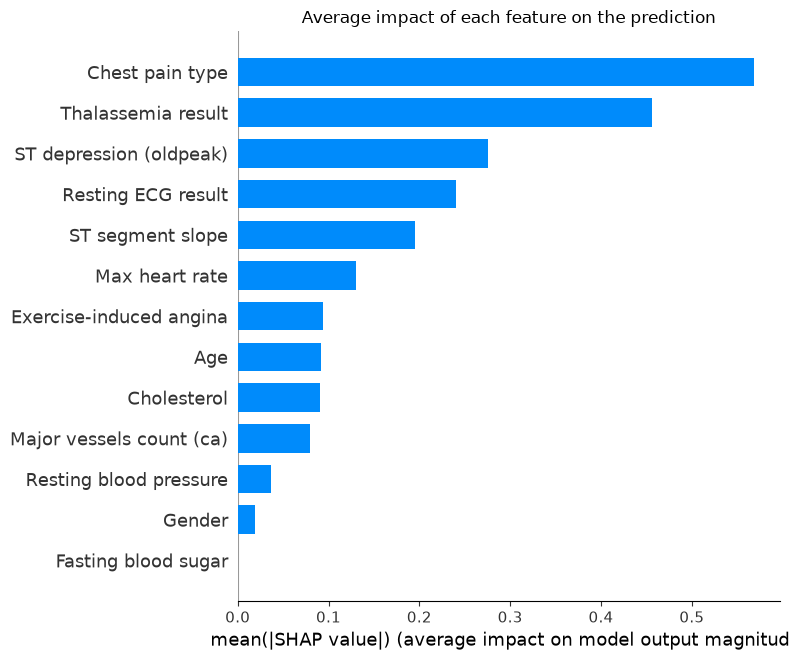

In [4]:
plt.figure()
shap.summary_plot(shap_values, X_test_readable, plot_type='bar', show=False)
plt.title('Average impact of each feature on the prediction')
plt.tight_layout()
plt.show()

## 3. Beeswarm plot — impact and direction

The bar chart above only shows how much each feature matters. This plot also shows which direction —
does a high or low value push the prediction toward heart disease?

Each dot is one patient. Red = high value of that feature, blue = low value. Dots to the right push
the prediction toward disease, dots to the left push it toward no disease.

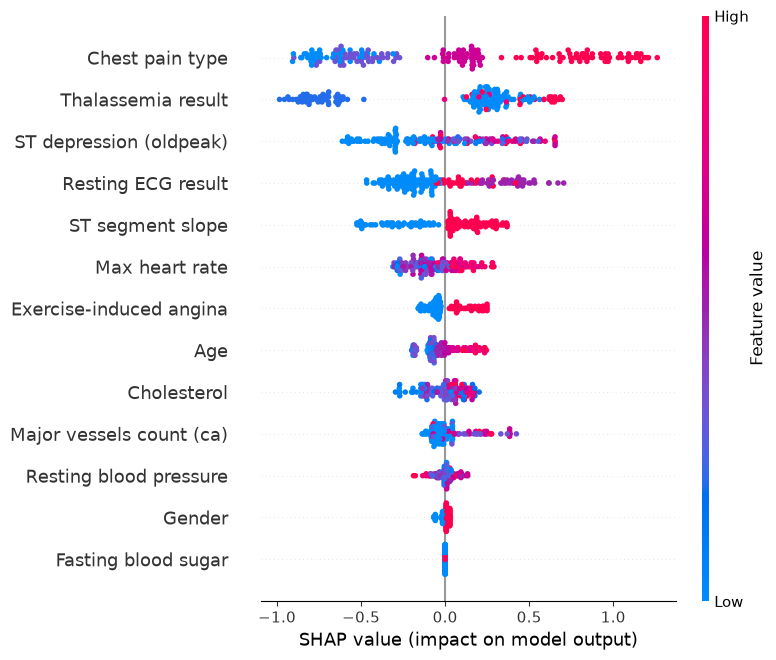

In [5]:
plt.figure()
shap.summary_plot(shap_values, X_test_readable, show=False)
plt.tight_layout()
plt.show()

**How to read this, feature by feature (top ones):**
- **Chest pain type:** the spread of colors shows this has a strong, mixed effect — certain chest
  pain types push risk up, others push it down (consistent with the asymptomatic finding from EDA)
- **Max heart rate:** blue dots (low heart rate) tend to sit on the right (pushing toward disease) —
  a lower max heart rate achieved during exercise is associated with higher predicted risk
- **ST depression (oldpeak):** red dots (high oldpeak) tend to push right — higher oldpeak values push
  toward a disease prediction
- **Exercise-induced angina, thalassemia result:** both show a clear color split left vs right,
  meaning the model leans on them consistently in one direction

## 4. Explaining one individual patient's prediction

This is where SHAP becomes genuinely useful in practice — not just 'the model is 80% accurate,' but
'here is exactly why this particular patient was flagged.'

We'll pick one patient from the test set who the model predicted as high-risk, and break down exactly
which features pushed that prediction up or down.

In [6]:
probs = model.predict_proba(X_test)[:, 1]
patient_idx = int(np.argmax(probs))

print(f"Patient index: {patient_idx}")
print(f"Model's predicted probability of heart disease: {probs[patient_idx]:.1%}")
print(f"Actual outcome: {'Heart disease' if y_test.iloc[patient_idx] == 1 else 'No heart disease'}")
print()
print("This patient's feature values:")
X_test_readable.iloc[patient_idx]

Patient index: 177
Model's predicted probability of heart disease: 96.0%
Actual outcome: Heart disease

This patient's feature values:


Age                          56.0
Gender                        0.0
Chest pain type               3.0
Resting blood pressure      200.0
Cholesterol                 288.0
Fasting blood sugar           1.0
Resting ECG result            2.0
Max heart rate              133.0
Exercise-induced angina       1.0
ST depression (oldpeak)       4.0
ST segment slope              3.0
Major vessels count (ca)      2.0
Thalassemia result            7.0
Name: 177, dtype: float64

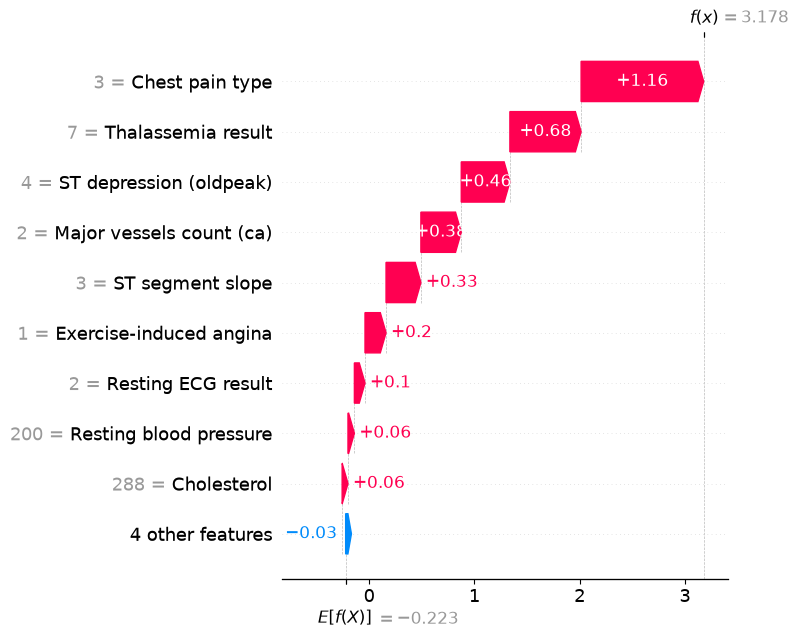

In [7]:
plt.figure()
shap.plots.waterfall(shap_values[patient_idx], show=False)
plt.tight_layout()
plt.show()

**How to read this waterfall chart:** it starts from the model's average prediction (E[f(x)], the
baseline) and shows, feature by feature, exactly how much each one pushed this specific patient's
prediction up (red) or down (blue) to arrive at the final value. This is the kind of explanation you
could realistically show a clinician for one patient — the model flagged this patient mainly because
of these specific factors.

This is also exactly the piece your literature review identified as missing from most prior work —
combining a tuned ensemble model with genuine per-patient explainability.

## Summary

- Used **SHAP with TreeExplainer** on the final tuned XGBoost model
- **Chest pain type, max heart rate, ST depression (oldpeak), exercise-induced angina, and
  thalassemia result** are the features the model relies on most — broadly consistent with the EDA,
  but now confirmed from the actual trained model's behaviour rather than raw statistics alone
- Demonstrated both **global** explainability (what matters overall) and **local** explainability
  (why one specific patient got their prediction) — directly addressing the explainability gap your
  literature review identified

Next step: **save the best model**, then **build the web app** around it.